# 06 - Error analysis

Deployed model at its balanced threshold. Training OOF predictions (614 patients) give more stable patterns than the 154-patient test set; both are shown. Patterns describe where the model struggles, not what causes diabetes.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
print(json.dumps(json.loads((M / 'error_analysis_summary.json').read_text()), indent=1))

{
 "test": {
  "threshold": 0.32,
  "counts": {
   "TP": 44,
   "FN": 10,
   "FP": 29,
   "TN": 71
  },
  "fn_share_with_glucose_below_126": 0.8,
  "tp_share_with_glucose_below_126": 0.29545454545454547,
  "fp_share_with_glucose_at_least_126": 0.7241379310344828,
  "tn_share_with_glucose_at_least_126": 0.09859154929577464,
  "fn_median_age": 27.5,
  "tp_median_age": 38.0,
  "fn_median_bmi": 29.3,
  "tp_median_bmi": 34.55,
  "mean_missing_inputs_by_type": {
   "FN": 1.3,
   "FP": 0.862,
   "TN": 0.944,
   "TP": 1.045
  },
  "n_borderline_0.10": 25,
  "error_rate_borderline_0.10": 0.32,
  "error_rate_confident_gt_0.30": 0.3055555555555556
 },
 "train_oof": {
  "threshold": 0.32,
  "counts": {
   "TP": 174,
   "FN": 40,
   "FP": 103,
   "TN": 297
  },
  "fn_share_with_glucose_below_126": 0.8,
  "tp_share_with_glucose_below_126": 0.21264367816091953,
  "fp_share_with_glucose_at_least_126": 0.5922330097087378,
  "tn_share_with_glucose_at_least_126": 0.10774410774410774,
  "fn_median_age": 2

## Median feature values per outcome type

In [3]:
display(pd.read_csv(M / 'error_profile_train_oof.csv', index_col=0))
display(pd.read_csv(M / 'error_profile_test.csv', index_col=0))

,n,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,proba,n_missing_inputs
error_type,,,,,,,,,,,
TP,174,5.0,152.0,76.0,34.0,180.0,34.90,0.511,37.5,0.6822,0.0
FN,40,2.0,109.0,70.0,28.5,115.0,31.80,0.379,28.0,0.1937,1.0
FP,103,4.0,129.0,77.0,32.0,176.0,34.05,0.430,37.0,0.5081,1.0
TN,297,2.0,101.0,68.0,24.0,83.0,28.60,0.313,25.0,0.1186,0.0


,n,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,proba,n_missing_inputs
error_type,,,,,,,,,,,
TP,44,4.5,144.5,77.0,32.0,194.5,34.55,0.438,38.0,0.7192,1.0
FN,10,3.5,116.5,64.0,29.0,115.0,29.30,0.299,27.5,0.1693,1.5
FP,29,4.0,139.0,80.0,37.0,194.0,35.70,0.329,29.0,0.5548,1.0
TN,71,2.0,99.5,69.0,23.0,94.0,26.90,0.294,25.0,0.0881,0.0


## False negatives vs true positives (both diabetic)

In [4]:
pd.read_csv(M / 'fn_vs_tp_train_oof.csv')

,feature,median_FN,median_TP,median_TN,FN_minus_TP
0,Pregnancies,2.000,5.000,2.000,-3.000
1,Glucose,109.000,152.000,101.000,-43.000
2,BloodPressure,70.000,76.000,68.000,-6.000
3,SkinThickness,28.500,34.000,24.000,-5.500
4,Insulin,115.000,180.000,83.000,-65.000
5,BMI,31.800,34.900,28.600,-3.100
6,DiabetesPedigreeFunction,0.379,0.511,0.313,-0.132
7,Age,28.000,37.500,25.000,-9.500


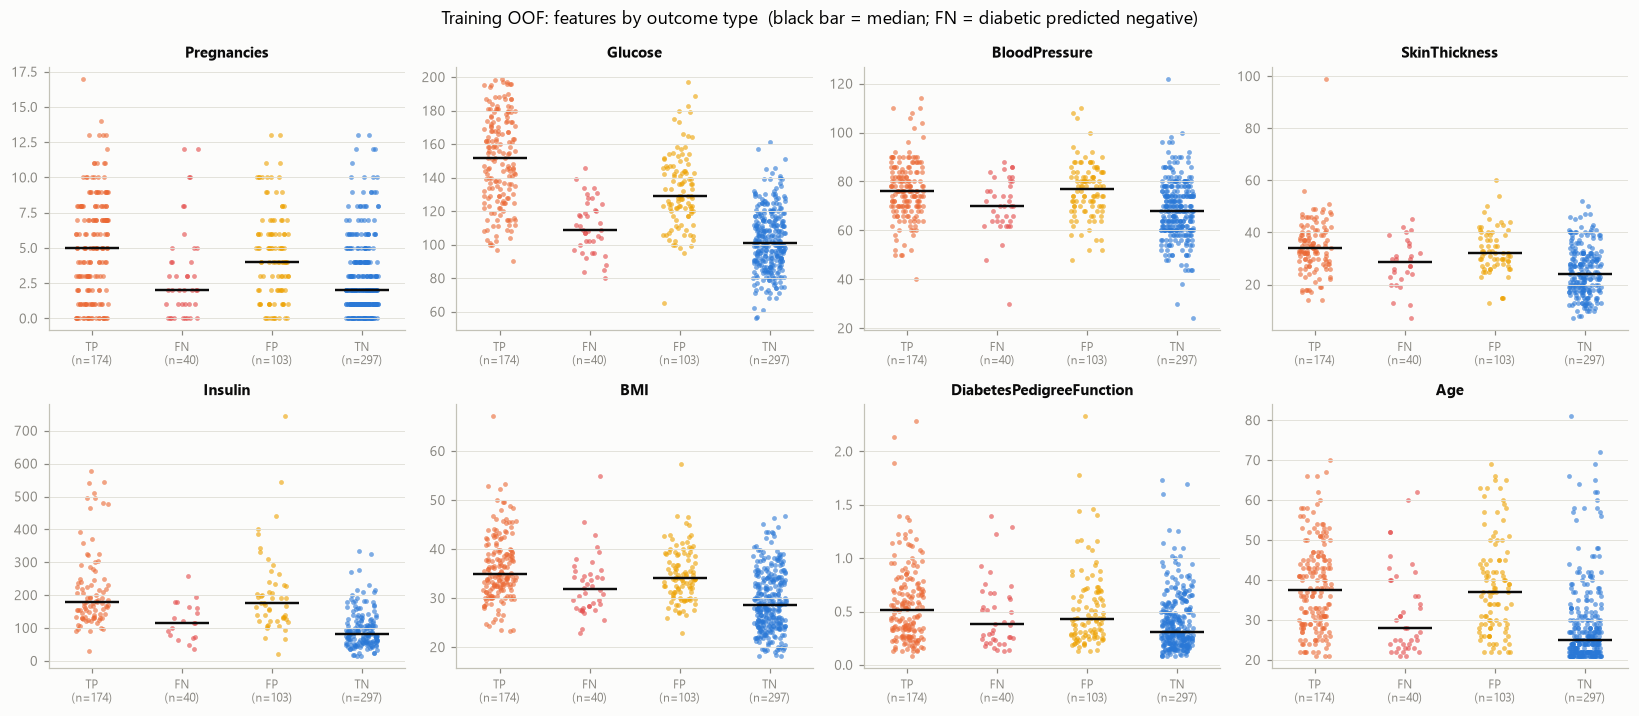

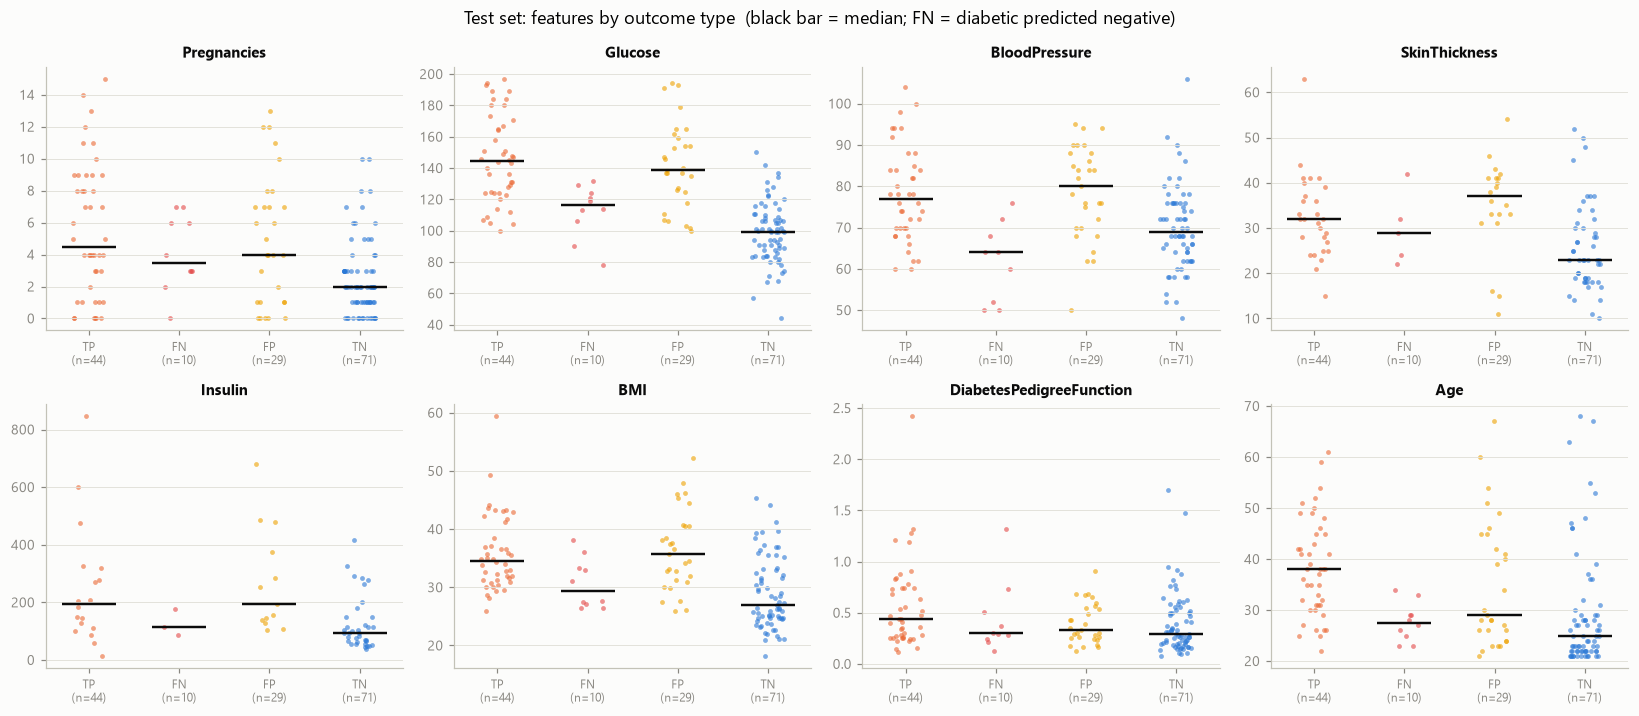

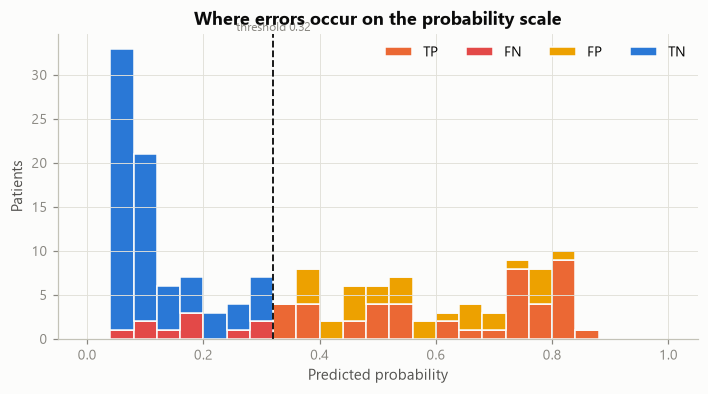

In [5]:
show('errors_oof_features.png'); show('errors_test_features.png'); show('errors_test_probability.png')

## Mean SHAP contribution by outcome type (test)

In [6]:
pd.read_csv(M / 'shap_mean_by_error_type_test.csv', index_col=0)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
error_type,,,,,,,,
FN,0.0022,-0.0981,-0.0114,-0.0065,0.0117,-0.0353,-0.0150,-0.0195
FP,0.0144,0.1080,0.0032,0.0062,0.0238,0.0626,-0.0029,0.0068
TN,-0.0063,-0.1346,-0.0011,-0.0099,-0.0045,-0.0419,-0.0110,-0.0268
TP,0.0192,0.1214,0.0040,0.0013,0.0185,0.0661,0.0072,0.0423


## Borderline cases (|p - threshold| <= 0.10, test)

In [7]:
pd.read_csv(M / 'borderline_cases_test.csv').head(20)

,row_id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,y_true,proba,y_pred,error_type,n_missing_inputs,distance_to_threshold
0,674,8,91.0,82.0,NaN,NaN,35.6,0.587,68,0,0.3182,0,TN,2,0.0018
1,402,5,136.0,84.0,41.0,88.0,35.0,0.286,35,1,0.3227,1,TP,0,0.0027
2,481,0,123.0,88.0,37.0,NaN,35.2,0.197,29,0,0.3153,0,TN,1,0.0047
3,630,7,114.0,64.0,NaN,NaN,27.4,0.732,34,1,0.3140,0,FN,2,0.0060
4,264,4,123.0,62.0,NaN,NaN,32.0,0.226,35,1,0.3331,1,TP,2,0.0131
5,17,7,107.0,74.0,NaN,NaN,29.6,0.254,31,1,0.3356,1,TP,2,0.0156
6,198,4,109.0,64.0,44.0,99.0,34.8,0.905,26,1,0.3420,1,TP,0,0.0220
7,700,2,122.0,76.0,27.0,200.0,35.9,0.483,26,0,0.2962,0,TN,0,0.0238
8,311,0,106.0,70.0,37.0,148.0,39.4,0.605,22,0,0.2958,0,TN,0,0.0242
9,162,0,114.0,80.0,34.0,285.0,44.2,0.167,27,0,0.2895,0,TN,0,0.0305


## False negatives on the test set

In [8]:
e = pd.read_csv(M / 'errors_test.csv'); e[e.error_type == 'FN'].sort_values('proba')

,row_id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,y_true,proba,y_pred,error_type,n_missing_inputs,distance_to_threshold
121,6,3,78.0,50.0,32.0,88.0,31.0,0.248,26,1,0.0622,0,FN,0,0.2578
46,276,7,106.0,60.0,24.0,NaN,26.5,0.296,29,1,0.1014,0,FN,1,0.2186
70,419,3,129.0,64.0,29.0,115.0,26.4,0.219,28,1,0.1083,0,FN,0,0.2117
14,678,3,121.0,52.0,NaN,NaN,36.0,0.127,25,1,0.1478,0,FN,2,0.1722
35,124,0,113.0,76.0,NaN,NaN,33.3,0.278,23,1,0.1681,0,FN,2,0.1519
145,38,2,90.0,68.0,42.0,NaN,38.2,0.503,27,1,0.1705,0,FN,1,0.1495
75,243,6,119.0,50.0,22.0,176.0,27.1,1.318,33,1,0.1953,0,FN,0,0.1247
93,366,6,124.0,72.0,NaN,NaN,27.6,0.368,29,1,0.2507,0,FN,2,0.0693
49,535,4,132.0,NaN,NaN,NaN,32.9,0.302,23,1,0.2841,0,FN,3,0.0359
3,630,7,114.0,64.0,NaN,NaN,27.4,0.732,34,1,0.3140,0,FN,2,0.0060
